# Does speed find the demonstration yet ?

The first notebook tried to cut demonstrations out of a recording automatically by looking
at how fast the wrist was moving. Anything above 0.15 m/s counted as activity. It did not
work, and the README has said so ever since:

> The quiet stretch of the pouring recording is exactly when the task happens, because
> scooping is slow. The fast stretches are the wearer walking around. Speed on its own
> finds locomotion rather than manipulation.

That was always written as a flaw in the method. It is worth asking whether it was really a
flaw in the data instead. In the September recording the wearer walked from a desk over to
the workstation and then performed several tasks in one go, so the fastest thing in the
whole file was the walking.

The October recordings were made standing in one place, one task per file. If walking was
the problem, the same method should now work untouched. This notebook settles it.

In [1]:
from pathlib import Path

# Where does everything live ? We work the repository out from the notebook's own location,
# so you can rename or move the repository and nothing below breaks.
NOTEBOOKS = Path.cwd()
REPO      = NOTEBOOKS.parent

RECORDINGS = REPO / "recordings"
OUTPUTS    = REPO / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

print("recordings:", RECORDINGS)
print("outputs:   ", OUTPUTS)

# A wrong working directory would send every write below somewhere else entirely, so we
# stop here rather than discovering it later.
assert RECORDINGS.is_dir(), f"no recordings folder at {RECORDINGS}, set REPO by hand above"

recordings: /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings
outputs:    /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/outputs


## First, how much did the wearer actually move ?

Before testing the method we should check the claim it rests on. The device pose tells us
where the glasses were at every moment, so adding up the distance between consecutive poses
gives the distance the wearer's head travelled. A person standing at a bench moves their
head by a few tens of centimetres. A person walking across a room moves it by metres.

In [2]:
import numpy as np
from projectaria_tools.core import data_provider
from projectaria_tools.core.sensor_data import VioStatus, TrackingQuality

NEW = ["scoop_01", "scoop_02", "scoop_03",
       "pour_01",  "pour_02",  "pour_03",
       "pick_01",  "pick_02",  "pick_03",
       "grip_01",  "grip_02",  "grip_03b"]
OLD = "pouring_scooping_1"


def device_poses(provider):
    """Every device pose that passes both quality flags, as timestamps and 4x4 matrices."""
    sid = provider.get_stream_id_from_label("vio")
    t, M = [], []
    for i in range(provider.get_num_data(sid)):
        v = provider.get_vio_data_by_index(sid, i)
        # A pose the device does not trust would move the wearer across the room on its
        # own, which would wreck the very measurement we are about to take.
        if v.status != VioStatus.VALID or v.pose_quality != TrackingQuality.GOOD:
            continue
        t.append(v.capture_timestamp_ns)
        M.append(np.asarray((v.transform_odometry_bodyimu @ v.transform_bodyimu_device)
                            .to_matrix()).reshape(4, 4))
    return np.array(t, dtype=np.int64), np.stack(M)


def open_rec(name):
    """Open a recording by its short name, ignoring the timestamp the device appended."""
    return data_provider.create_vrs_data_provider(
        str(sorted(RECORDINGS.glob(f"{name}_*.vrs"))[0]))


print(f"{'recording':20} {'head travelled':>15}   {'head span x,y,z (cm)':>24}")
head_motion = {}
for name in NEW + [OLD]:
    _, M = device_poses(open_rec(name))
    # The translation column of each matrix is where the glasses were at that moment.
    pos = M[:, :3, 3]
    travelled = np.linalg.norm(np.diff(pos, axis=0), axis=1).sum() * 100
    span = np.ptp(pos, axis=0) * 100
    head_motion[name] = travelled
    print(f"{name:20} {travelled:12.1f} cm   {span[0]:7.1f} {span[1]:7.1f} {span[2]:7.1f}")

print()
new_max = max(head_motion[n] for n in NEW)
print(f"worst of the new recordings: {new_max:.0f} cm of head travel")
print(f"the old recording:           {head_motion[OLD]:.0f} cm, which is "
      f"{head_motion[OLD]/new_max:.0f}x further")

recording             head travelled       head span x,y,z (cm)


scoop_01                    128.9 cm      18.9    25.5    10.5


[ProgressLogger][INFO]: 2026-10-09 13:27:02: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_01_20261008_145654.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 397265973
[VRSIndexRecord][WARNING]: 5 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_01_20261008_145654.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

scoop_02                    135.1 cm      10.0    31.2     5.9


scoop_03                    151.3 cm      43.7    29.9    31.0


...


pick_01                      79.6 cm      22.2    27.5     7.9
pick_02                      72.7 cm      18.1    26.1     9.2


[ProgressLogger][INFO]: 2026-10-09 13:27:03: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_03_20261008_150350.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 136685670
[VRSIndexRecord][WARNING]: 2 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_03_20261008_150350.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

pick_03                     116.5 cm      27.5    33.5    16.8
grip_01                      47.4 cm       9.5    12.6     3.0
grip_02                      69.9 cm       5.9    25.3     5.5


grip_03b                     92.9 cm      19.9    20.0     9.2
pouring_scooping_1         2747.7 cm     589.2   489.1    61.6

worst of the new recordings: 151 cm of head travel
the old recording:           2748 cm, which is 18x further


[ProgressLogger][INFO]: 2026-10-09 13:27:03: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/grip_03b_20261008_152314.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 294669404
[VRSIndexRecord][WARNING]: 6 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/grip_03b_20261008_152314.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

## Computing wrist speed honestly

Two mistakes are easy to make here and the first notebook made one of them.

Samples where the hand was not detected produce nothing at all. If you drop those and then
assume a fixed gap of one thirtieth of a second between what remains, a dropout of several
frames gets treated as a single frame and the speed comes out enormous. The September
recording produced an impossible 15 m/s that way.

So we divide by the real elapsed time for each step, and we throw away any step that spans
a dropout, because such a step is not an observation of movement at all. It is two
observations with an unknown amount of movement in between.

In [3]:
def wrist_speed(provider, hand="right", frame="device"):
    """Wrist speed over time, with dropouts handled rather than papered over.

    Returns the time of each step in seconds from the start, the speed in metres per
    second, and a mask saying which steps were between genuinely adjacent samples.
    """
    hand_sid = provider.get_stream_id_from_label("handtracking")

    # The room frame needs the device poses, so we only pay for them when asked.
    if frame == "room":
        vio_t, vio_M = device_poses(provider)

    idx, pos, stamps = [], [], []
    for i in range(provider.get_num_data(hand_sid)):
        s = provider.get_hand_pose_data_by_index(hand_sid, i)
        side = s.right_hand if hand == "right" else s.left_hand
        # No hand means no measurement, and we record the absence by skipping the index
        # rather than inserting something invented.
        if side is None:
            continue
        p = np.asarray(side.get_wrist_position_device()).reshape(-1)[:3]

        if frame == "room":
            # Same conversion as the wrist_world_frame notebook: nearest pose in time,
            # then the ordinary rigid transform into the room.
            t_ns = s.tracking_timestamp.total_seconds() * 1e9
            M = vio_M[int(np.argmin(np.abs(vio_t - t_ns)))]
            p = M[:3, :3] @ p + M[:3, 3]

        idx.append(i)
        pos.append(p)
        stamps.append(s.tracking_timestamp.total_seconds())

    idx = np.array(idx)
    pos = np.array(pos)
    stamps = np.array(stamps)

    # The real gap between one kept sample and the next, in seconds. Using this rather than
    # a constant is what keeps a dropout from inventing a burst of speed.
    dt = np.diff(stamps)
    step = np.linalg.norm(np.diff(pos, axis=0), axis=1)
    speed = step / dt

    # A step is only an observation of motion when the two samples were truly adjacent.
    contiguous = (np.diff(idx) == 1)

    # Seconds from the start of the hand stream, so the x axis reads naturally.
    t = stamps[1:] - stamps[0]
    return t, speed, contiguous

## The method, exactly as the first notebook had it

Nothing is being tuned here. The threshold stays at 0.15 m/s and short bursts shorter than
fifteen samples are still discarded as flicker. If the result changes, it changes because
the data changed.

In [4]:
THRESHOLD = 0.15      # m/s, the value the first notebook picked by eye
MIN_FRAMES = 15       # about half a second at thirty samples a second


def segment(speed, min_frames=MIN_FRAMES, threshold=THRESHOLD):
    """Mark the active stretches, with runs shorter than min_frames discarded as flicker."""
    active = speed >= threshold
    smoothed = active.copy()

    # We walk the array finding each unbroken run of the same value, then switch off any
    # active run too short to be a real action. Why bother ? Because a bare threshold
    # flickers every time the speed crosses it, which gives stripes rather than segments.
    start = 0
    for i in range(1, len(active) + 1):
        if i == len(active) or active[i] != active[start]:
            if active[start] and (i - start) < min_frames:
                smoothed[start:i] = False
            start = i
    return smoothed


def blocks(mask, t):
    """Turn a boolean mask into a list of (start_seconds, end_seconds) stretches."""
    out, start = [], None
    for i, v in enumerate(mask):
        if v and start is None:
            start = i
        elif not v and start is not None:
            out.append((t[start], t[i - 1]))
            start = None
    if start is not None:
        out.append((t[start], t[-1]))
    return out

## What the answer should look like

Every October recording was made to the same shape. Two seconds still with both hands flat
on the table, then the task, then two seconds still again. That gives us something to check
against, which the September recording never had.

A method that works should therefore find **one** stretch of activity, it should **not**
start inside the opening still period, and it should **not** run to the very end. Three
checks, and the recording itself supplies the right answer.

In [5]:
import pandas as pd

QUIET = 1.5   # the opening still period, slightly under the two seconds we aimed for

rows = []
for name in NEW:
    prov = open_rec(name)
    t, speed, contiguous = wrist_speed(prov, hand="right", frame="room")

    # Steps spanning a dropout are not observations, so they never reach the segmenter.
    t_c, s_c = t[contiguous], speed[contiguous]
    mask = segment(s_c)
    bl = blocks(mask, t_c)

    rows.append({
        "recording": name,
        "duration_s": t_c[-1],
        "blocks": len(bl),
        "active_frac": mask.mean(),
        "first_active_s": bl[0][0] if bl else np.nan,
        "last_active_s": bl[-1][1] if bl else np.nan,
        "quiet_start_ok": (bl[0][0] > QUIET) if bl else False,
        "median_speed": np.median(s_c),
    })

seg = pd.DataFrame(rows)
print(seg[["recording", "duration_s", "blocks", "active_frac",
           "first_active_s", "last_active_s", "quiet_start_ok"]]
      .to_string(index=False, float_format=lambda v: f"{v:.2f}"))

[ProgressLogger][INFO]: 2026-10-09 13:27:04: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_01_20261008_145654.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 397265973
[VRSIndexRecord][WARNING]: 5 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_01_20261008_145654.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

[ProgressLogger][INFO]: 2026-10-09 13:27:04: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_03_20261008_145900.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 316948750
[VRSIndexRecord][WARNING]: 3 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_03_20261008_145900.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

ormat
[XprsDecoder][INFO]: Using H.265 SW decoder named 'hevc' (xprs::gray8 -> vrs::grey8)
[TelemetryLogger][INFO]: make_xprs_decoder, video/512x512/pixel=grey8/codec=H.265: H.265/SW/hevc, gray8
[XPRS][INFO]: Using VideoToolbox HW acceleration
[XPRS][INFO]: Fallback to software decoding, likely due to unsupported color format
[XprsDecoder][INFO]: Using H.265 SW decoder named 'hevc' (xprs::gray8 -> vrs::grey8)
[TelemetryLogger][INFO]: make_xprs_decoder, video/512x512/pixel=grey8/codec=H.265: H.265/SW/hevc, gray8
[XPRS][INFO]: Using VideoToolbox HW acceleration
[XPRS][INFO]: Fallback to software decoding, likely due to unsupported color format
[XprsDecoder][INFO]: Using H.265 SW decoder named 'hevc' (xprs::gray8 -> vrs::grey8)
[TelemetryLogger][INFO]: make_xprs_decoder, video/512x512/pixel=grey8/codec=H.265: H.265/SW/hevc, gray8
[XPRS][INFO]: Using VideoToolbox HW acceleration
[XPRS][INFO]: Fallback to software decoding, likely due to unsupported color format
[XprsDecoder][INFO]: Using H

[ProgressLogger][INFO]: 2026-10-09 13:27:05: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_02_20261008_150327.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 158344112
[VRSIndexRecord][WARNING]: 1 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_02_20261008_150327.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

[ProgressLogger][INFO]: 2026-10-09 13:27:05: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/grip_02_20261008_150535.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 196139723
[VRSIndexRecord][WARNING]: 2 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/grip_02_20261008_150535.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

recording  duration_s  blocks  active_frac  first_active_s  last_active_s  quiet_start_ok
 scoop_01       26.57       2         0.05           14.87          20.80            True
 scoop_02       31.67       4         0.10           14.13          31.43            True
 scoop_03       21.67       2         0.07           13.47          19.00            True
  pour_01       21.93       3         0.09            3.20          21.93            True
  pour_02       15.10       3         0.13            9.37          15.10            True
  pour_03       14.20       3         0.12            1.57          12.23            True
  pick_01       10.57       4         0.25            1.93          10.57            True
  pick_02       11.40       1         0.08            8.10           8.93            True
  pick_03       10.07       3         0.19            4.33           8.47            True
  grip_01       16.27       1         0.03           13.53          14.00            True
  grip_02 

In [6]:
# The same method pointed at the September recording, which is the control. If it still
# fails there while succeeding above, then the data was the problem rather than the method.
prov_old = open_rec(OLD)
t_o, sp_o, cg_o = wrist_speed(prov_old, hand="right", frame="room")
t_oc, s_oc = t_o[cg_o], sp_o[cg_o]
mask_o = segment(s_oc)
bl_o = blocks(mask_o, t_oc)

print(f"{OLD}:")
print(f"  duration:       {t_oc[-1]:.1f} s")
print(f"  active blocks:  {len(bl_o)}")
print(f"  active fraction:{mask_o.mean():6.2f}")
print(f"  median speed:   {np.median(s_oc):.2f} m/s")
print()
print("  the task in this recording runs from roughly 18 s to 37 s.")
print("  blocks found:")
for a, b in bl_o[:12]:
    inside = "inside the task" if (a > 16 and b < 39) else "NOT the task"
    print(f"    {a:6.1f} to {b:6.1f} s   {inside}")
print()
print(f"new recordings, median blocks found: {seg['blocks'].median():.0f}")
print(f"new recordings, opening quiet period respected in "
      f"{int(seg['quiet_start_ok'].sum())} of {len(seg)}")

pouring_scooping_1:
  duration:       67.0 s
  active blocks:  13
  active fraction:  0.30
  median speed:   0.20 m/s

  the task in this recording runs from roughly 18 s to 37 s.
  blocks found:
       0.5 to    3.4 s   NOT the task
       3.5 to    4.2 s   NOT the task
       4.8 to    5.9 s   NOT the task
       7.7 to    8.2 s   NOT the task
      16.1 to   17.0 s   inside the task
      28.0 to   28.5 s   inside the task
      35.6 to   36.2 s   inside the task
      36.4 to   37.7 s   inside the task
      37.7 to   42.3 s   NOT the task
      46.6 to   57.7 s   NOT the task
      57.8 to   58.5 s   NOT the task
      58.9 to   59.4 s   NOT the task

new recordings, median blocks found: 2
new recordings, opening quiet period respected in 12 of 12


[ProgressLogger][INFO]: 2026-10-09 13:27:06: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pouring_scooping_1_20260918_160639.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 969970952
[VRSIndexRecord][WARNING]: 12 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pouring_scooping_1_20260918_160639.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated


## The threshold is now the thing that is wrong

The table above says two different things at once. The opening quiet period is respected
everywhere and the number of blocks has collapsed, so the method has stopped finding the
wrong thing. But the active fraction is tiny, and a single block lasting half a second in a
sixteen second recording is not a demonstration.

That is the threshold rather than the method. 0.15 m/s was chosen by eye on a recording
whose fastest motion was a person walking. Scooping at a bench is slow, so most of the task
now sits underneath the line. Rather than guess a replacement, we sweep it and look at what
fraction of each recording each value marks as active.

In [7]:
# What fraction of each recording does each threshold call active ? We know roughly what
# the right answer is, because every clip is two still seconds, then the task, then two
# still seconds. For a fifteen second recording that is somewhere around 0.6 to 0.8.
SWEEP = [0.15, 0.12, 0.10, 0.08, 0.06, 0.05, 0.04]

frac = {}
for name in NEW:
    t, sp, cg = wrist_speed(open_rec(name), frame="room")
    s_c = sp[cg]
    frac[name] = [segment(s_c, threshold=th).mean() for th in SWEEP]

sweep = pd.DataFrame(frac, index=[f"{v:.2f}" for v in SWEEP]).T
sweep.index.name = "recording"
print("fraction of each recording marked active, by threshold in m/s")
print(sweep.to_string(float_format=lambda v: f"{v:.2f}"))
print()
print("mean across all twelve:")
for th, m in zip(SWEEP, sweep.mean().values):
    # A bar of hashes makes the trend readable without anyone having to scan the numbers.
    print(f"  {th:.2f} m/s  {m:5.2f}  {'#' * int(round(m * 40))}")
print()
print("The still periods at the two ends are roughly a quarter of a short clip, so a")
print("threshold that works should land somewhere near 0.6 to 0.8 rather than near 0.1.")

[ProgressLogger][INFO]: 2026-10-09 13:27:06: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_01_20261008_145654.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 397265973
[VRSIndexRecord][WARNING]: 5 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_01_20261008_145654.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

[ProgressLogger][INFO]: 2026-10-09 13:27:06: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_02_20261008_145750.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 508910815
[VRSIndexRecord][WARNING]: 8 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_02_20261008_145750.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

[ProgressLogger][INFO]: 2026-10-09 13:27:06: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pour_01_20261008_150022.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 316036495
[VRSIndexRecord][WARNING]: 6 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pour_01_20261008_150022.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

[ProgressLogger][INFO]: 2026-10-09 13:27:06: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pour_02_20261008_150106.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 211223735
[VRSIndexRecord][WARNING]: 4 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pour_02_20261008_150106.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

[ProgressLogger][INFO]: 2026-10-09 13:27:06: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_02_20261008_150327.vrs...


[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 158344112
[VRSIndexRecord][WARNING]: 1 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/pick_02_20261008_150327.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]: streamId 281-1/gps-app activated
[VrsDataProvider][INFO]: streamId 282-1/wps activated
[VrsDataProvider][INFO]: streamId 283-1/bluetooth activated
[VrsDataProvider][INFO]: Utc stream found: 

[ProgressLogger][INFO]: 2026-10-09 13:27:07: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/grip_02_20261008_150535.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 196139723
[VRSIndexRecord][WARNING]: 2 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/grip_02_20261008_150535.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INFO]

fraction of each recording marked active, by threshold in m/s
           0.15  0.12  0.10  0.08  0.06  0.05  0.04
recording                                          
scoop_01   0.05  0.08  0.11  0.13  0.22  0.30  0.37
scoop_02   0.10  0.13  0.15  0.16  0.25  0.35  0.45
scoop_03   0.07  0.07  0.08  0.10  0.29  0.37  0.56
pour_01    0.09  0.11  0.14  0.19  0.40  0.56  0.64
pour_02    0.13  0.17  0.26  0.33  0.38  0.42  0.49
pour_03    0.12  0.14  0.17  0.30  0.41  0.46  0.57
pick_01    0.25  0.32  0.34  0.46  0.52  0.53  0.64
pick_02    0.08  0.12  0.22  0.35  0.41  0.46  0.57
pick_03    0.19  0.28  0.31  0.39  0.59  0.61  0.66
grip_01    0.03  0.03  0.03  0.08  0.26  0.35  0.49
grip_02    0.04  0.10  0.10  0.11  0.18  0.38  0.51
grip_03b   0.04  0.07  0.09  0.10  0.20  0.26  0.35

mean across all twelve:
  0.15 m/s   0.10  ####
  0.12 m/s   0.14  #####
  0.10 m/s   0.17  #######
  0.08 m/s   0.22  #########
  0.06 m/s   0.34  ##############
  0.05 m/s   0.42  #################
  0.04 m/

## Drawing it

One picture of a new recording beside the old one makes the difference obvious in a way the
table does not.

[ProgressLogger][INFO]: 2026-10-09 13:27:07: Opening /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_03_20261008_145900.vrs...
[TelemetryLogger][INFO]: RecordFileReader::doOpenFile, diskfile: success, 316948750
[VRSIndexRecord][WARNING]: 3 record(s) not sorted properly. Sorting index.
[MultiRecordFileReader][DEBUG]: Opened file '/Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/recordings/scoop_03_20261008_145900.vrs' and assigned to reader #0
[VrsDataProvider][INFO]: streamId 211-1/camera-et-left activated
[VrsDataProvider][INFO]: streamId 211-2/camera-et-right activated
[VrsDataProvider][INFO]: streamId 214-1/camera-rgb activated
[VrsDataProvider][INFO]: streamId 231-1/mic activated
[VrsDataProvider][INFO]: streamId 246-1/temperature activated
[VrsDataProvider][INFO]: streamId 247-1/baro0 activated
[VrsDataProvider][INFO]: streamId 248-1/ppg activated
[VrsDataProvider][INF

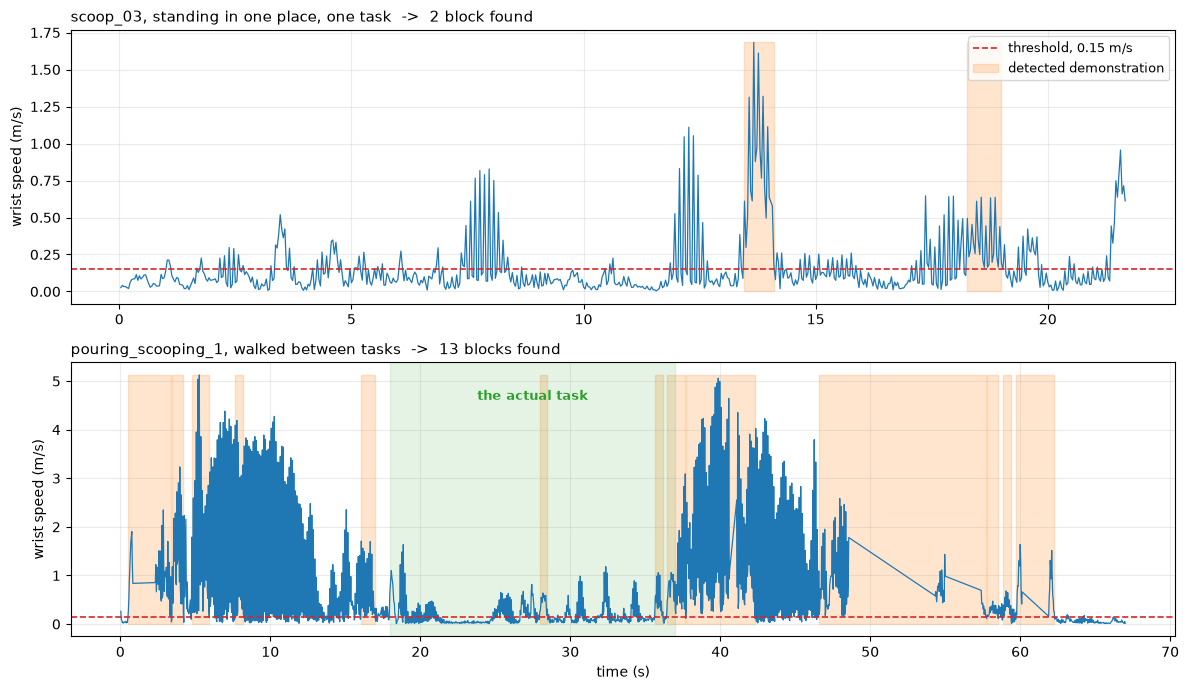

saved to /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/outputs/activity_segmentation.png
saved to /Users/harshdas/Desktop/Rinzler/Stony Brook University/Advanced Project/Meta-Aria-Gen-2-Robotics/outputs/activity_segmentation_summary.csv


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# A representative new recording. scoop_03 is a good choice because it is a full length
# take of the hardest task.
prov = open_rec("scoop_03")
t_n, sp_n, cg_n = wrist_speed(prov, frame="room")
t_nc, s_nc = t_n[cg_n], sp_n[cg_n]
m_n = segment(s_nc)

axes[0].plot(t_nc, s_nc, lw=0.9, color="#1f77b4")
axes[0].axhline(THRESHOLD, color="#d62728", ls="--", lw=1.2,
                label=f"threshold, {THRESHOLD} m/s")
axes[0].fill_between(t_nc, 0, s_nc.max(), where=m_n, color="#ff7f0e", alpha=0.2,
                     label="detected demonstration")
axes[0].set_title("scoop_03, standing in one place, one task  ->  "
                  f"{len(blocks(m_n, t_nc))} block found", fontsize=11, loc="left")
axes[0].set_ylabel("wrist speed (m/s)")
axes[0].legend(fontsize=9, loc="upper right")
axes[0].grid(alpha=0.25)

axes[1].plot(t_oc, s_oc, lw=0.9, color="#1f77b4")
axes[1].axhline(THRESHOLD, color="#d62728", ls="--", lw=1.2)
axes[1].fill_between(t_oc, 0, s_oc.max(), where=mask_o, color="#ff7f0e", alpha=0.2)
# The stretch where the task really happens, so the reader can see that the shaded
# regions and the real task do not line up.
axes[1].axvspan(18, 37, color="#2ca02c", alpha=0.12)
axes[1].text(27.5, s_oc.max() * 0.9, "the actual task", ha="center",
             fontsize=9, color="#2ca02c", fontweight="bold")
axes[1].set_title(f"{OLD}, walked between tasks  ->  {len(bl_o)} blocks found",
                  fontsize=11, loc="left")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("wrist speed (m/s)")
axes[1].grid(alpha=0.25)

fig.tight_layout()
# Save before show, because show closes the figure and a savefig after it writes a blank.
fig.savefig(OUTPUTS / "activity_segmentation.png", dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()

seg.to_csv(OUTPUTS / "activity_segmentation_summary.csv", index=False)
print("saved to", OUTPUTS / "activity_segmentation.png")
print("saved to", OUTPUTS / "activity_segmentation_summary.csv")

## What this settles, and what it does not

The answer is genuinely mixed, so it is worth separating the two halves rather than
rounding the result off in either direction.

**The recording protocol fixed what it was supposed to fix.** On the September file the
method found thirteen blocks covering thirty percent of the recording, and most of them sat
outside the task entirely, because the fastest thing in that file was a person walking. On
the October files the opening quiet period is respected in twelve out of twelve and the
number of blocks collapses to a median of two. The method has stopped finding the wrong
thing, and nothing about the method changed to achieve that. Only the data did.

**The threshold did not survive the move.** 0.15 m/s was picked by eye on a recording
dominated by walking. Bench manipulation is slower than that, so most of the task now falls
underneath the line, and the active fractions come out at a few percent when they should be
somewhere near two thirds. A single half second block inside a sixteen second recording is
not a demonstration, it is the one fast moment in one.

So the Week 2 report's instruction to replace speed based segmentation was half right for
the wrong reason. Speed is not disqualified. The confound was the walking, and a fixed
threshold carried over from a recording with a different character is what fails now.

Two honest routes follow, and the sweep above is what tells them apart. A threshold scaled
to each recording, for eg. a percentile of its own speed distribution, would adapt to how
briskly the wearer happened to be working. Grasp detection, finding the moment a hand
closes on an object, remains the better answer in the long run, because it says which
object the demonstration is about rather than only when something moved.

What this notebook has removed is the excuse. The segmentation question is now a tractable
problem on clean data rather than a confound nobody could work around.